# The same method on refreshing data: domestic incidents in Chicago

**Nicholas Soulakis, PhD** · October 2026

**Summary.** The signal method from the injury notebook, unchanged, on ten years of Chicago Reported Crimes (City of Chicago Data Portal, 2.46 million reports, 2016-10-16 to 2026-10-08). The case definition is a domestic incident. The strongest signals fall on New Year's Day every year, and the line list shows why that needs an analyst before anyone acts.

*Adapted from Methods in Health and Biomedical Informatics (HSIP 441), Northwestern University Feinberg School of Medicine.*

## Why it matters

Domestic violence is a public health problem, and police reports are one of the few sources that arrive every day. A city that watches them daily can see a change while it is still happening. The same reports also carry administrative quirks, and a surveillance system has to tell the two apart.

In [1]:
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("../utils").exists():
    os.system("git clone -q https://github.com/nsoulakis/public_health_surveillance")
    os.chdir("public_health_surveillance/python/notebooks")
sys.path.insert(0, "..")

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from utils.crime import code_cases, read_crimes
from utils.settings import CRIME_THRESHOLDS, WINDOW
from utils.signals import daily_series, flag_summary, zscore_signals

raw = sorted(Path("../../data/raw/crime").glob("Crimes_*.csv"))
demo = Path("../../data/demo/crime")
FULL = bool(raw)
if FULL:
    df = code_cases(read_crimes(raw[-1]))
    daily = daily_series(df, "domestic_case", date_col="date", weight_col=None)
else:
    daily = pd.read_csv(demo / "crime_daily_domestic.csv", index_col=0, parse_dates=True)
print("Mode:", "full data" if FULL else "demo (full-data daily counts)", "| data end",
      daily.index.max().date())

Mode: full data | data end 2026-10-08


## The method

Case definition: a report flagged *domestic* by the Chicago Police Department. Then exactly the injury notebook's signal method: a 14-day baseline, the residual, a z-score against the previous 14 residuals, and a flag above the threshold, for the daily count and for the ratio of domestic to all other reports. No survey weights here; police reports are a count of everything reported, not a sample.

In [3]:
results = {("domestic", m): zscore_signals(daily[m], WINDOW, t)
           for (_, m), t in CRIME_THRESHOLDS.items()}
flag_summary(results)

,definition,measure,days,flags,flags_per_100_days,top_flag_date,top_z
0,domestic,case_sum,3617,44,1.22,2017-01-01,20.00
1,domestic,ratio_to_other,3617,42,1.16,2019-12-25,11.75


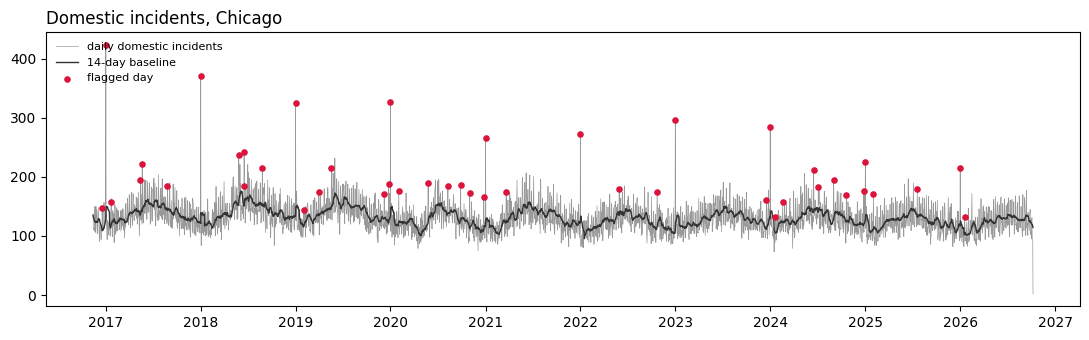

In [4]:
res = results[("domestic", "case_sum")]
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(res.index, res["value"], lw=0.5, color="0.6", label="daily domestic incidents")
ax.plot(res.index, res["moving_avg"], lw=1, color="0.2", label=f"{WINDOW}-day baseline")
ax.scatter(res.index[res["flag"]], res["value"][res["flag"]], color="crimson", s=14,
           label="flagged day", zorder=3)
ax.set_title("Domestic incidents, Chicago", loc="left")
ax.legend(loc="upper left", frameon=False, fontsize=8)
fig.tight_layout()

## The line list: is it worth pulling case files?

The strongest flag, compared with its own 14-day baseline, by type of report.

In [5]:
top = res["z"].idxmax()
if FULL:
    near = df[(df["date"] >= top - pd.Timedelta(days=WINDOW)) & (df["date"] <= top)]
    records = near[near["domestic_case"] == 1]
else:
    records = pd.read_csv(demo / "crime_linelist_records.csv", parse_dates=["date"])
day = records[records["date"] == top]
base = records[records["date"] < top]
compare = pd.DataFrame({"flag_day": day["primary_type"].value_counts(),
                        "baseline_per_day": base["primary_type"].value_counts() / WINDOW})
print(f"{top.date()}: {len(day)} domestic reports")
compare.fillna(0).round(1).sort_values("flag_day", ascending=False).head(8)

2017-01-01: 424 domestic reports


,flag_day,baseline_per_day
primary_type,,
OFFENSE INVOLVING CHILDREN,153.0,4.4
BATTERY,124.0,72.0
OTHER OFFENSE,44.0,17.1
SEX OFFENSE,36.0,0.5
ASSAULT,21.0,14.0
CRIMINAL DAMAGE,13.0,9.1
THEFT,11.0,6.4
CRIMINAL SEXUAL ASSAULT,9.0,0.1


In [6]:
cols = ["date", "primary_type", "description", "location_description", "arrest"]
day[cols].head(15)

,date,primary_type,description,location_description,arrest
2403848,2017-01-01,BATTERY,DOMESTIC BATTERY SIMPLE,RESIDENCE,True
2403853,2017-01-01,BATTERY,DOMESTIC BATTERY SIMPLE,BAR OR TAVERN,False
2403855,2017-01-01,OTHER OFFENSE,TELEPHONE THREAT,RESIDENCE,False
2403856,2017-01-01,THEFT,OVER $500,APARTMENT,False
2403867,2017-01-01,BATTERY,DOMESTIC BATTERY SIMPLE,RESIDENCE,False
2403871,2017-01-01,BATTERY,DOMESTIC BATTERY SIMPLE,APARTMENT,False
2403873,2017-01-01,BATTERY,DOMESTIC BATTERY SIMPLE,PARKING LOT/GARAGE(NON.RESID.),False
2403875,2017-01-01,BATTERY,DOMESTIC BATTERY SIMPLE,ALLEY,False
2403879,2017-01-01,BATTERY,SIMPLE,RESIDENCE,True
2403884,2017-01-01,OTHER OFFENSE,VIOLATE ORDER OF PROTECTION,RESIDENCE PORCH/HALLWAY,True


**Pull case files: yes for the batteries, no for the rest.** January 1, 2017: domestic battery is up by about 70% over its baseline, a real New Year's increase worth a call. Offenses involving children and sex offenses jump thirty-fold on the same day, and do so every January 1: they look like reports whose start date is unknown and is recorded as New Year's Day. That is a data artifact, not an outbreak, and pulling those files would chase the calendar.

## Where else it works

Any daily administrative feed carries both real change and recording habits: 311 calls, emergency medical service runs, child welfare hotlines. The method finds the unusual day; the line list is where an analyst separates the event from the artifact.

## Going further

- Drop January 1 from the series and rerun: what becomes the strongest flag?
- Compare the count and ratio measures across the 2020 pandemic, when all reporting fell.
- Split by community area to see whether a flag is citywide or local.